# 05 · ESRI baseline: reproduce the deployed 13.80% and measure it on Guinea

The methodology document (`Methodology_LandUse_Guinea_v2.docx`, §7.1) reports **Figure of Merit 13.80%** for the recommended Expander-only mode: ESRI 10 m land cover on a 250 m grid, trained on earlier years, tested on a one-year hold-out, with the observed amount of each transition supplied so that only *where* change happens is scored.

This notebook:

1. reproduces 13.80% exactly, using the deployed package's own allocation and
   scoring functions on the saved run;
2. checks **which pixels** that score covers, and **which years**;
3. computes the baseline correctly, on Guinea only.

**Inputs.** The GeoTIFFs exported by the run behind the document
(`E:/SDG AI Lab/Guinea/Land Use-Deforestation/outputs_tiff_landuse2`, copied to
`data/esri_deployed_run_250m/`), and that run's cached ESRI maps for 2017–2025
(copied to `data/esri/`).

**Code.** `landuse_tool` from `Land Use-Deforestation/`, imported read-only:
`prediction.run_allocation_simulation`, `change_analysis.calculate_transition_matrix`,
`validation.figure_of_merit`.

In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H          # also puts Land Use-Deforestation/ on the path for landuse_tool
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio
from landuse_tool import change_analysis as ca, prediction as pred
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
RERUN = False        # True: redo the Guinea-only re-allocation (~30 s)
REQUERY_GEE = False  # True: re-list the ESRI collection's dates from Earth Engine (needs credentials)

R = H.DEPLOYED_RUN
baseline, prof = H.read_tif(R / "01_actual_lastTrainingYear.tif")
observed, _ = H.read_tif(R / "02_actual_holdoutYear.tif")
inside = H.guinea_mask(prof)
print(f"Grid: {prof['width']} × {prof['height']} px, {prof['transform'].a:.7f}° "
      f"(= {prof['transform'].a * 111320:.0f} m north–south), CRS {prof['crs']}")

Grid: 3443 × 2444 px, 0.0022458° (= 250 m north–south), CRS EPSG:4326


## 1 · Reproduce the published figures

In [2]:
runs = {"Expander-only": "Expander_only_package_", "Patcher-only": "Patcher_only_package_",
        "Growth-mode (dilation)": "Growth_mode_package_dilation_"}
published = {"Expander-only": (13.80, 85.76), "Patcher-only": (11.94, 84.22), "Growth-mode (dilation)": (13.73, 86.07)}
sims = {m: H.read_tif(R / "_package_validation" / d / "predicted_land_cover.tif")[0] for m, d in runs.items()}
everywhere = np.ones_like(inside)
rows = []
for m, s in sims.items():
    r = H.score(baseline, observed, s, everywhere)
    rows.append((m, published[m][0], r["figure_of_merit_pct"], published[m][1], r["model_accuracy_pct"],
                 r["null_model_accuracy_pct"], r["observed_change_px"]))
repro = pd.DataFrame(rows, columns=["Mode", "Document FoM %", "Rescored FoM %", "Document accuracy %",
                                    "Rescored accuracy %", "No-change accuracy %", "Observed changes"])
H.show(repro)

Mode,Document FoM %,Rescored FoM %,Document accuracy %,Rescored accuracy %,No-change accuracy %,Observed changes
Expander-only,13.80,13.80,85.76,85.76,89.10,769625
Patcher-only,11.94,11.94,84.22,84.22,89.10,769625
Growth-mode (dilation),13.73,13.73,86.07,86.07,89.10,769625


**Reproduced exactly**, including the 769,625 observed changes and 89.10%
"no change" accuracy the document quotes.

## 2 · Study Area Check

In [3]:
valid = ~(np.isin(baseline, H.ESRI_INVALID) | np.isin(observed, H.ESRI_INVALID))
changed = valid & (baseline != observed)
lat = prof["transform"].f + prof["transform"].e * (np.arange(prof["height"]) + 0.5)
cell_km2 = (250 * 250 * np.cos(np.radians(lat)) / 1e6)[:, None] * np.ones((1, prof["width"]))
area = pd.DataFrame([
    ("Whole grid (bounding box)", prof["width"] * prof["height"], None, None),
    ("Inside Guinea's boundary", int(inside.sum()), float(cell_km2[inside].sum()), None),
    ("Scored in the published hold-out", int(valid.sum()), float(cell_km2[valid].sum()), int(changed.sum())),
    ("  of which inside Guinea", int((valid & inside).sum()), float(cell_km2[valid & inside].sum()), int((changed & inside).sum())),
    ("  of which OUTSIDE Guinea", int((valid & ~inside).sum()), float(cell_km2[valid & ~inside].sum()), int((changed & ~inside).sum())),
], columns=["", "Pixels", "Area km²", "Observed changes"])
H.show(area, 0)

,Pixels,Area km²,Observed changes
Whole grid (bounding box),8414692,,
Inside Guinea's boundary,4010676,246466,
Scored in the published hold-out,7057727,433968,769625
of which inside Guinea,4010676,246466,507539
of which OUTSIDE Guinea,3047051,187502,262086


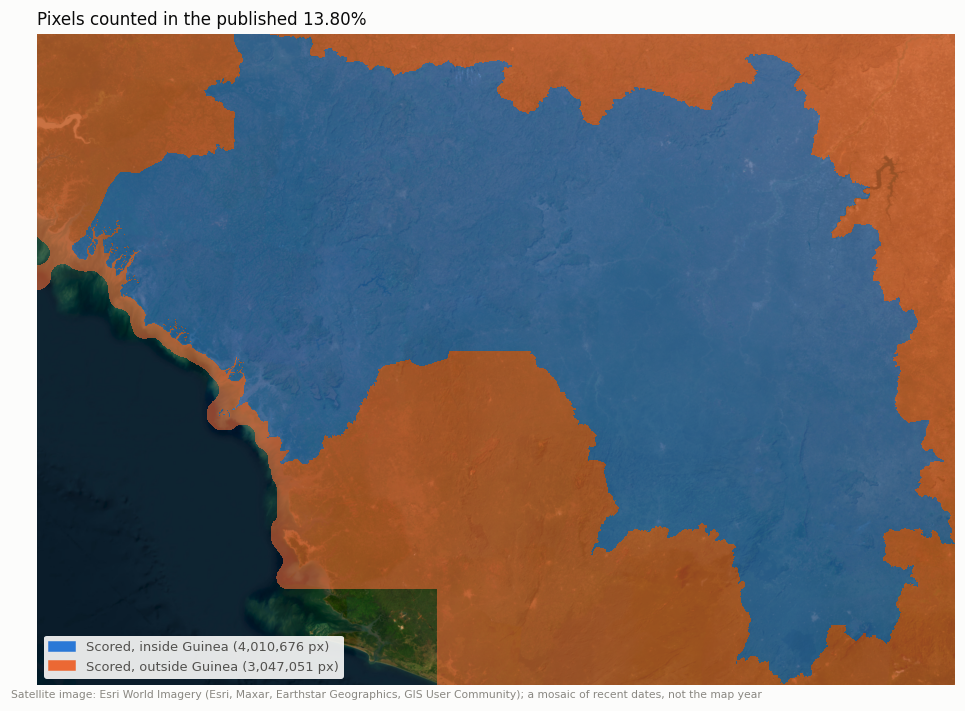

In [4]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
view = np.zeros(baseline.shape, np.uint8)
view[valid & inside] = 1
view[valid & ~inside] = 2
fig, ax = plt.subplots(figsize=(9, 6.4))
H.plot_satellite(ax, prof)
ax.imshow(np.ma.masked_equal(view, 0), cmap=ListedColormap(["#ffffff", H.SERIES[0], H.SERIES[1]]), vmin=0, vmax=2,
          interpolation="nearest", alpha=0.6)
ax.legend(handles=[Patch(color=H.SERIES[0], label=f"Scored, inside Guinea ({(valid & inside).sum():,} px)"),
                   Patch(color=H.SERIES[1], label=f"Scored, outside Guinea ({(valid & ~inside).sum():,} px)")],
          loc="lower left", frameon=True, facecolor=H.SURFACE, edgecolor="none", framealpha=0.9, fontsize=8.5, labelcolor=H.INK_2)
ax.set_axis_off()
ax.set_title("Pixels counted in the published 13.80%", loc="left", color=H.INK, fontsize=11)
H.satellite_credit(fig)
plt.tight_layout(); plt.show()

**43% of the scored pixels, and a third of the scored changes, are outside Guinea:** parts or neighboring countries that fall inside Guinea's bounding box. 

## 3 · Temporal Range Check

In [5]:
cache = {y: H.read_tif(H.DATA / "esri" / f"ESRI_LULC_{y}.tif")[0] for y in range(2017, 2026)}
match = pd.DataFrame([(label, *[int(((cache[y] != m) & (m != 0) & (m != 255) & (cache[y] != 0)).sum()) for y in cache])
                      for label, m in [("Run's 'last training year' (labelled 2023)", baseline),
                                       ("Run's 'hold-out year' (labelled 2024)", observed)]],
                     columns=["Map", *[str(y) for y in cache]])
H.show(match.set_index("Map").T.reset_index().rename(columns={"index": "Cached ESRI year (pixels that differ)"}), 0)

Cached ESRI year (pixels that differ),Run's 'last training year' (labelled 2023),Run's 'hold-out year' (labelled 2024)
2017,1377648,1200128
2018,1061906,1127152
2019,1019537,1128707
2020,970243,996561
2021,940600,975000
2022,766696,949008
2023,663894,841660
2024,0,769625
2025,769625,0


In [6]:
dates_file = H.SUMMARY / "05_esri_collection_dates.csv"
if REQUERY_GEE:
    import ee, glob, os, time, csv
    from dotenv import dotenv_values
    env = dotenv_values(H.LANDUSE_TOOL_PARENT / ".env")
    keys = [str(H.LANDUSE_TOOL_PARENT / "landuse_tool" / (env.get("GEE_SA_KEY_FILE") or ""))] + \
           glob.glob(str(H.LANDUSE_TOOL_PARENT / "landuse_tool" / "credentials" / "*.json"))
    key = next(k for k in keys if os.path.isfile(k) and "client_email" in json.load(open(k)))
    ee.Initialize(ee.ServiceAccountCredentials(json.load(open(key))["client_email"], key), project=env.get("GEE_PROJECT_ID"))
    coll = ee.ImageCollection("projects/sat-io/open-datasets/landcover/ESRI_Global-LULC_10m_TS").filterBounds(ee.Geometry.Point([-11.0, 10.5]))
    feats = coll.map(lambda i: ee.Feature(None, {"id": i.id(), "start": i.get("system:time_start"), "end": i.get("system:time_end")})).getInfo()["features"]
    fmt = lambda ms: time.strftime("%Y-%m-%d", time.gmtime(ms / 1000))
    pd.DataFrame(sorted([(f["properties"]["id"], fmt(f["properties"]["start"]), fmt(f["properties"]["end"]), time.strftime("%Y-%m-%d"))
                         for f in feats], key=lambda r: r[1]),
                 columns=["image_id_at_guinea_point", "start", "end", "queried"]).to_csv(dates_file, index=False)
H.show(pd.read_csv(dates_file), 0)

image_id_at_guinea_point,start,end,queried
29P_2017,2017-01-01,2017-12-31,2026-10-19
29P_2018,2018-01-01,2018-12-31,2026-10-19
29P_2019,2019-01-01,2019-12-31,2026-10-19
29P_2020,2020-01-01,2020-12-31,2026-10-19
29P_2021,2021-01-01,2021-12-31,2026-10-19
29P_2022,2022-01-01,2022-12-31,2026-10-19
29P_2023,2023-01-01,2023-12-31,2026-10-19
29P_2024,2024-01-01,2024-12-31,2026-10-19
29P_20250101-20251231,2025-01-01,2025-12-31,2026-10-19


The run's "2023" map **is** ESRI 2024 and its "2024" hold-out **is** ESRI 2025. The cache is labelled
correctly.

**This does not invalidate the result.** The hold-out year was withheld before any training. 
Only the labels are wrong: the published validation is **trained on 2017–2024 and tested on 2024→2025**. Anything the document attributes to "2023–2024" is really 2024→2025.

## 4 · The baseline on Guinea

Count the observed demand inside Guinea, allow only Guinea pixels to change, and rerun the deployed `run_allocation_simulation` with the run's own suitability surfaces. Then score inside Guinea.

In [7]:
W = H.OUTPUTS / "esri_baseline"
b_g = H.write_masked_copy(R / "01_actual_lastTrainingYear.tif", W / "baseline_2024_guinea.tif", inside)
o_g = H.write_masked_copy(R / "02_actual_holdoutYear.tif", W / "observed_2025_guinea.tif", inside)
_, counts, _ = ca.calculate_transition_matrix(str(b_g), str(o_g), nodata_value=255)
keep = [c for c in counts.index if c not in H.ESRI_INVALID]
counts = counts.loc[keep, keep]
atlases = H.deployed_atlases()
trained = set(atlases["Expander-only"]) | set(atlases["Patcher-only"])
demand = int(counts.values.sum() - np.trace(counts.values))
covered = sum(int(counts.loc[f, t]) for f, t in trained if f in counts.index and t in counts.columns)
print(f"Observed gross demand inside Guinea: {demand:,} px; covered by a trained surface: {covered:,} ({100 * covered / demand:.1f}%)")

import logging; logging.getLogger("landuse_tool.prediction").setLevel(logging.ERROR)  # untrained small transitions warn
guinea = {}
for mode, atlas in atlases.items():
    out_dir = W / mode.split()[0].replace("-", "_")
    path = out_dir / "predicted_land_cover.tif"
    if RERUN or not path.exists():
        out_dir.mkdir(parents=True, exist_ok=True)
        path = pred.run_allocation_simulation(lc_end_file=str(b_g), transition_counts=counts,
                                              suitability_paths=atlas, temp_dir=str(out_dir), stochastic=False)
    guinea[mode] = H.read_tif(path)[0]
outside_changes = {m: int(((s != baseline) & ~inside & ~np.isin(s, H.ESRI_INVALID)).sum()) for m, s in guinea.items()}
print("Pixels changed outside Guinea by the re-allocation:", outside_changes)

Observed gross demand inside Guinea: 507,539 px; covered by a trained surface: 503,657 (99.2%)
Pixels changed outside Guinea by the re-allocation: {'Expander-only': 0, 'Patcher-only': 0, 'Growth-mode (dilation)': 0}


In [8]:
rows = []
for m in runs:
    a = H.score(baseline, observed, sims[m], everywhere)
    c = H.score(baseline, observed, guinea[m], inside)
    rows.append((m, a["figure_of_merit_pct"], c["figure_of_merit_pct"],
                 c["model_accuracy_pct"], c["null_model_accuracy_pct"], c["hits"], c["false_alarms"]))
guinea_baseline = pd.DataFrame(rows, columns=["Mode", "Published (whole box) FoM %", "Guinea FoM %", "Accuracy %",
                                              "No-change accuracy %", "Hits", "False alarms"])
H.show(guinea_baseline)

Mode,Published (whole box) FoM %,Guinea FoM %,Accuracy %,No-change accuracy %,Hits,False alarms
Expander-only,13.80,17.32,83.94,87.35,134979,271696
Patcher-only,11.94,13.04,81.75,87.35,109767,334051
Growth-mode (dilation),13.73,16.60,84.02,87.35,127630,261116


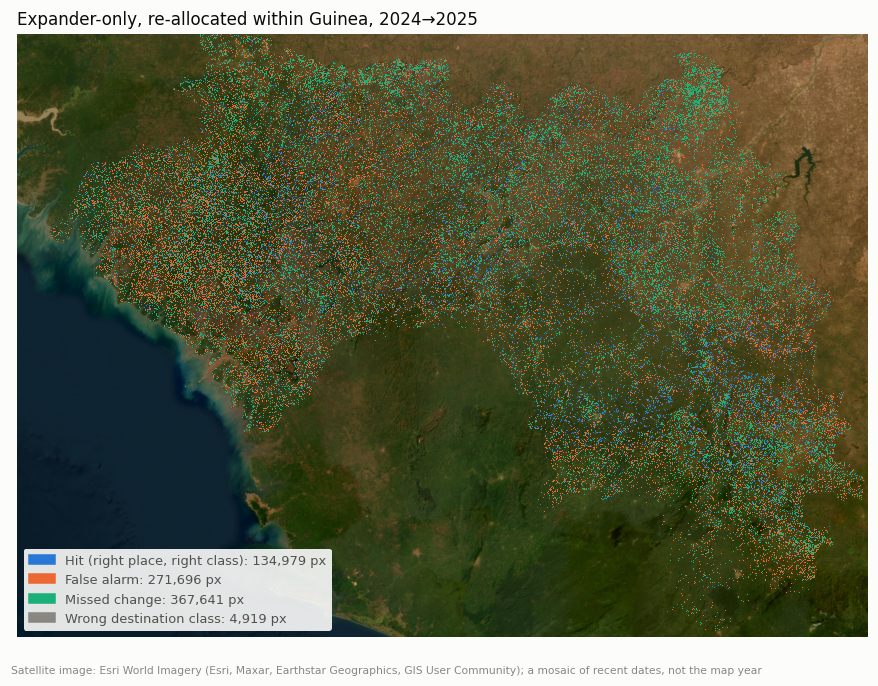

In [9]:
codes = H.outcome_map(baseline, observed, guinea["Expander-only"], inside & valid)
H.plot_outcome_map(codes, "Expander-only, re-allocated within Guinea, 2024→2025", profile=prof)
plt.tight_layout(); plt.show()

## Summary: the baseline

| | Value |
|---|---|
| Published (document §7.1) | **13.80%** FoM, Expander-only. Reproduced exactly |
| What it actually measured | Hold-out **2024→2025** (labelled 2023→2024), over Guinea **plus 3.0 M pixels of neighbouring countries** |
| **Baseline on Guinea, 2024→2025** | **Expander-only 17.32%** (Patcher-only 13.04%, Growth-mode 16.60%) |

The deployed method does *better* on Guinea (17.32%) than the published figure. The run placed almost no change outside the boundary (34,645 of the 262,086 changes observed there), because its predictors were blanked outside Guinea, so those changes counted as misses and dragged the published score down.

**One caveat:** the suitability surfaces here are the ones the original run
trained. Notebook 06 retrains the deployed method from scratch, Guinea-only,
as the first row of every comparison, which settles this. Every improvement is
compared against *that* row, on the same pixels and years.

**Points to edit on the document**: §4.3 and §7.1 should state the hold-out as
2024→2025, and the scored area should be the boundary-clipped one. The 13.80% then
becomes 17.32% once the method is retrained Guinea-only and confirmed in notebook 06.

In [10]:
H.SUMMARY.mkdir(parents=True, exist_ok=True)
repro.to_csv(H.SUMMARY / "05_reproduce_published.csv", index=False)
area.to_csv(H.SUMMARY / "05_scored_area.csv", index=False)
match.to_csv(H.SUMMARY / "05_year_match.csv", index=False)
guinea_baseline.to_csv(H.SUMMARY / "05_baseline.csv", index=False)
print("Saved tables to", H.SUMMARY.relative_to(H.ROOT))

Saved tables to outputs\summary
